# Actividad: Entrenamiento y Optimización de Redes Neuronales para Habitabilidad de Exoplanetas

## 1. Consumo y preprocesamiento de datos
Conectamos con la API de la NASA Exoplanet Archive y seleccionamos las características relevantes.

In [7]:
import pandas as pd
import requests
from io import StringIO

'''
Glosario de Variables del Catálogo de Exoplanetas
Variable	Descripción
🧾 Identificadores
pl_name	Nombre oficial del exoplaneta (ej. Kepler-22 b).
pl_name_normalized	Nombre del planeta en formato estandarizado (sin espacios ni caracteres especiales).
hostname	Nombre de la estrella anfitriona (ej. Kepler-22).
🔭 Descubrimiento
discoverymethod	Método de detección del exoplaneta (ej. Transit, Radial Velocity).
disc_year	Año en que se confirmó el descubrimiento del planeta.
disc_facility	Instalación o misión responsable del descubrimiento (ej. Kepler, TESS).
🪐 Propiedades del planeta
pl_orbsmax	Semieje mayor de la órbita en unidades astronómicas (AU).
pl_rade	Radio del planeta en radios terrestres (R⊕).
pl_radj	Radio del planeta en radios jovianos (R♃).
pl_masse	Masa del planeta en masas terrestres (M⊕).
pl_massj	Masa absoluta del planeta en masas jovianas (M♃), si está disponible.
pl_bmassj	Masa del planeta en masas jovianas (M♃).
pl_bmasse	Masa mínima estimada del planeta en masas terrestres.
pl_eqt	Temperatura de equilibrio del planeta en kelvin (K).
🌟 Estrella anfitriona
st_spectype	Tipo espectral de la estrella (ej. G2V, M3).
st_mass	Masa de la estrella en masas solares (M☉).
'''

# Consulta ADQL sin pl_habitable
query = "select pl_name, pl_rade, pl_bmasse, pl_orbsmax, pl_eqt, st_spectype from pscomppars"
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
params = {
    "query": query,
    "format": "csv"
}

try:
    response = requests.get(url, params=params)
    response.raise_for_status()
    df = pd.read_csv(StringIO(response.text))
except requests.HTTPError as e:
    print('HTTPError:', e)
    print('Respuesta del servidor:')
    print(response.text)
    raise

# Renombrar columnas
df = df.rename(columns={
    'pl_rade': 'radius',
    'pl_bmasse': 'mass',
    'pl_orbsmax': 'distance',
    'pl_eqt': 'temperature',
    'st_spectype': 'star_type'
})

df.head()

,pl_name,radius,mass,distance,temperature,star_type
0,Kepler-334 d,1.41,2.57,0.1680,656.0,NaN
1,Kepler-251 d,2.77,8.10,0.1820,536.0,NaN
2,Kepler-729 b,3.58,12.50,0.0432,1273.0,NaN
3,Kepler-687 b,3.52,12.20,0.1326,518.0,NaN
4,Kepler-119 b,3.60,12.60,0.0350,1213.0,NaN


### Limpieza de datos
Eliminamos filas con valores nulos o incorrectos y codificamos variables categóricas.

In [8]:
# Eliminamos filas con valores nulos en las columnas seleccionadas
df = df.dropna(subset=['radius','mass','distance','temperature','star_type'])
# Creamos la variable objetivo 'habitable' usando criterios físicos simples
df['habitable'] = (
    (df['temperature'] >= 180) & (df['temperature'] <= 310) &
    (df['radius'] >= 0.5) & (df['radius'] <= 2.5)
 ).astype(int)
# Codificamos el tipo de estrella usando One-Hot Encoding
df = pd.get_dummies(df, columns=['star_type'], drop_first=True)
df.head()

,pl_name,radius,mass,distance,temperature,habitable,star_type_A0 V,star_type_A1 IV-V,star_type_A2 V,star_type_A5,...,star_type_M6 V,star_type_M6.5+/-0.5,star_type_M7.0 V,star_type_M7.25,star_type_M7.5,star_type_M8,star_type_M9,star_type_M9-L1,star_type_T8.5,star_type_m3 V
15,TOI-220 b,3.030000,13.800000,0.08911,805.0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
16,HD 23472 d,0.750000,0.550000,0.04298,909.0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
19,GJ 338 B b,3.250000,10.600000,0.14200,391.0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
22,TOI-411 c,2.328000,9.720000,0.10170,931.0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
27,HAT-P-51 b,13.506822,97.573321,0.05042,1168.2,0,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 2. Creación de la red neuronal
Definimos una red neuronal con tres capas ocultas, activación ReLU y regularización Dropout.

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Definimos variables de entrada y salida
X = df.drop(['pl_name','habitable'], axis=1)
y = df['habitable']
# Normalizamos las variables numéricas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Dividimos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
# Definimos el modelo
# model = keras.Sequential([
#     layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
#     layers.Dropout(0.2),
#     layers.Dense(16, activation='relu'),
#     layers.Dropout(0.2),
#     layers.Dense(8, activation='relu'),
#     layers.Dense(1, activation='sigmoid')
# ])

model = keras.Sequential([
    layers.Dense(32, activation='relu', input_shape=(X_train.shape[1],), kernel_regularizer=keras.regularizers.l2(0.001)),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001)),
    layers.Dropout(0.2),
    layers.Dense(8, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001)),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

c:\Users\adria\miniconda3\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │         6,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169 (28.00 KB)

 Trainable params: 7,169 (28.00 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrenamiento del modelo
Entrenamos la red neuronal y validamos el rendimiento.

In [10]:
history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_data=(X_test, y_test), verbose=1)

Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8324 - loss: 0.5645 - val_accuracy: 0.9655 - val_loss: 0.3149
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9632 - loss: 0.2763 - val_accuracy: 0.9655 - val_loss: 0.2503
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9665 - loss: 0.2304 - val_accuracy: 0.9655 - val_loss: 0.2317
Epoch 4/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9643 - loss: 0.2202 - val_accuracy: 0.9655 - val_loss: 0.2242
Epoch 5/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9654 - loss: 0.1878 - val_accuracy: 0.9655 - val_loss: 0.2215
Epoch 6/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9654 - loss: 0.1740 - val_accuracy: 0.9655 - val_loss: 0.2139
Epoch 7/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9665 - loss: 0.1639 - val_accuracy: 0.9655 - val_loss: 0.2167
Epoch 8/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9676 - loss: 0.1512 - val_accuracy: 0.9655 - val_loss:

## 4. Realización de predicciones
Seleccionamos un exoplaneta real, transformamos sus valores y predecimos la probabilidad de habitabilidad.

In [11]:
# Seleccionamos un exoplaneta del conjunto de prueba
sample = X_test[0].reshape(1, -1)
prob = model.predict(sample)[0][0]
print(f'Probabilidad de habitabilidad del exoplaneta: {prob:.2f}')
print('Etiqueta real:', y_test.iloc[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Probabilidad de habitabilidad del exoplaneta: 0.01
Etiqueta real: 0


## 5. Análisis y visualización de resultados
Graficamos la pérdida y precisión durante el entrenamiento y comparamos la predicción con la etiqueta real.

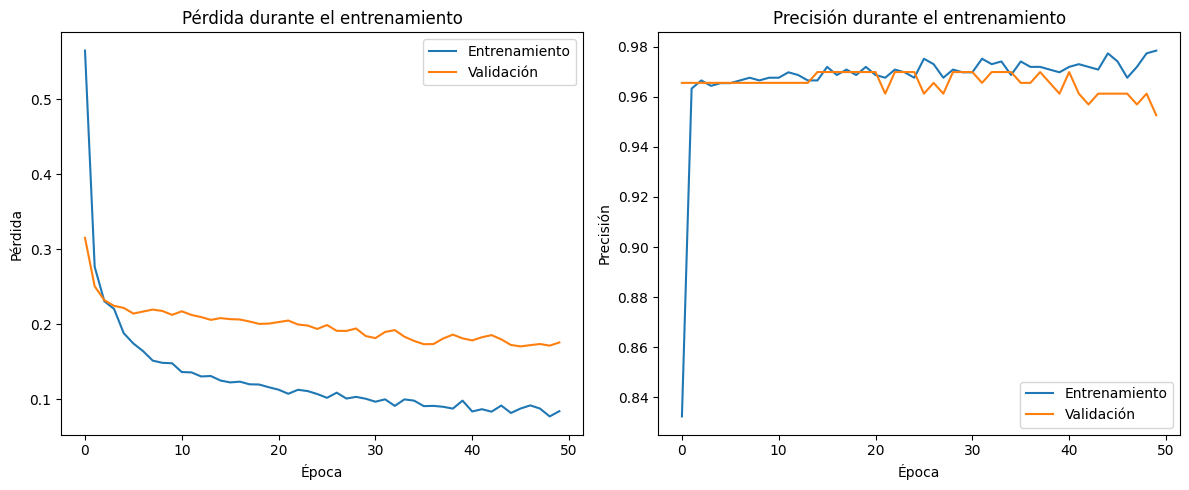

: 

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.tight_layout()
plt.show()